In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from systems_final_project.data.config import REPO_ROOT

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

df = pd.read_parquet(REPO_ROOT / "data" / "clean" / "hourly.parquet")
print(df.shape)
print(df.index.min(), "->", df.index.max())
df.columns.tolist()

# this loads the cleaned hourly data from the parquet file and prints the shape, index range, and column names of the DataFrame.

(97369, 23)
2015-10-01 00:00:00+00:00 -> 2026-11-09 00:00:00+00:00


['point',
 'braddock',
 'elizabeth',
 'sutersville',
 'natrona',
 'kittanning',
 'point_filled',
 'braddock_filled',
 'elizabeth_filled',
 'sutersville_filled',
 'natrona_filled',
 'kittanning_filled',
 'post_dam3',
 'rain_pittsburgh',
 'rain_fcst_pittsburgh',
 'rain_kittanning',
 'rain_fcst_kittanning',
 'rain_elizabeth',
 'rain_fcst_elizabeth',
 'rain_sutersville',
 'rain_fcst_sutersville',
 'rain_basin_mean',
 'water_year']

In [2]:
TARGET = "point"
HORIZON = 6          # hours ahead; start with 6, then repeat for 12 and 24
THRESHOLD = 20       # ft, the elevated-water level

# can change these to get different models 

In [3]:
df["y"] = df[TARGET].shift(-HORIZON)
df[[TARGET, "y"]].head(10)

# creates the target value that we should predict. 



,point,y
time,,
2015-10-01 00:00:00+00:00,NaN,16.9925
2015-10-01 01:00:00+00:00,NaN,16.9700
2015-10-01 02:00:00+00:00,NaN,16.9100
2015-10-01 03:00:00+00:00,NaN,16.8325
2015-10-01 04:00:00+00:00,NaN,16.7425
2015-10-01 05:00:00+00:00,16.9800,16.6525
2015-10-01 06:00:00+00:00,16.9925,16.5775
2015-10-01 07:00:00+00:00,16.9700,16.5200
2015-10-01 08:00:00+00:00,16.9100,16.4725


In [4]:
t = df.index[100]
print("time t:         ", t)
print("y at t:         ", df.at[t, "y"])
print("point at t + 6h:", df.at[t + pd.Timedelta(hours=HORIZON), TARGET])

time t:          2015-10-05 04:00:00+00:00
y at t:          16.78
point at t + 6h: 16.78


In [5]:
# next we use the baseline model persistence 

TEST_YEARS = range(2019, 2027)
HIGH = 18            # ft: also score "high water" hours separately

def score(y_true, y_pred):
    err = y_pred - y_true
    high = y_true >= HIGH
    return pd.Series({
        "rmse": np.sqrt((err ** 2).mean()),
        "mae": err.abs().mean(),
        "rmse_high": np.sqrt((err[high] ** 2).mean()),
        "n": len(err),
        "n_high": high.sum(),
    })

test = df[df.water_year.isin(TEST_YEARS)].dropna(subset=[TARGET, "y"])
print(len(test), "test hours")
print((test.y >= HIGH).sum(), f"of them have y >= {HIGH} ft")
print((test.y >= THRESHOLD).sum(), f"of them have y >= {THRESHOLD} ft")

70128 test hours
1047 of them have y >= 18 ft
358 of them have y >= 20 ft


In [ ]:
# baseline 1 is persistence; the idea is that in 6 hours it will be what it is now.
pred_persist = test[TARGET]          # "in 6 hours it will be what it is now"
score(test.y, pred_persist).round(3)

rmse             0.247
mae              0.171
rmse_high        0.981
n            70128.000
n_high        1047.000
dtype: float64

In [7]:
# baseline 2 is persitence + trend, the idea is that the river keeps changing at the same rate as it has been changing in the last 6 hours.
TREND_HOURS = 6
rate = (df[TARGET] - df[TARGET].shift(TREND_HOURS)) / TREND_HOURS   # ft per hour, last 6 h
pred_trend = (df[TARGET] + rate * HORIZON).loc[test.index]

ok = pred_trend.notna()
score(test.y[ok], pred_trend[ok]).round(3)

rmse             0.300
mae              0.217
rmse_high        0.660
n            70128.000
n_high        1047.000
dtype: float64

In [8]:
common = test.index[ok]
pd.DataFrame({
    "persistence": score(test.y[common], pred_persist[common]),
    "persistence+trend": score(test.y[common], pred_trend[common]),
}).T.round(3)

,rmse,mae,rmse_high,n,n_high
persistence,0.247,0.171,0.981,70128.0,1047.0
persistence+trend,0.300,0.217,0.660,70128.0,1047.0


In [12]:
if "rain_allegheny" not in df:
    df["rain_allegheny"] = df["rain_kittanning"]
    df["rain_mon"] = df[["rain_elizabeth", "rain_sutersville"]].mean(axis=1)

In [13]:
# it looks like the persistence model is better overall, because most of the time the river is flat with small wiggles, trend baseline is much better at high water (0.66 vs 0.98), next we try linear regression 

UPSTREAM = ["braddock", "sutersville", "natrona", "kittanning"]   # Elizabeth left out for now
RAIN = ["rain_allegheny", "rain_mon", "rain_pittsburgh"]

feats = pd.DataFrame(index=df.index)

# The Point itself: where it is now and how fast it's changing
feats["point_now"] = df[TARGET]
for k in [1, 3, 6]:
    feats[f"point_d{k}h"] = df[TARGET] - df[TARGET].shift(k)

# Upstream gauges: changes, not levels (immune to the Dam 3 shift at Braddock)
for g in UPSTREAM:
    for k in [1, 3, 6]:
        feats[f"{g}_d{k}h"] = df[g] - df[g].shift(k)

# Rain: totals over the past 6, 24, 48 h
for r in RAIN:
    for w in [6, 24, 48]:
        feats[f"{r}_sum{w}h"] = df[r].rolling(w, min_periods=w).sum()

print(feats.shape)
feats.columns.tolist()

(97369, 25)


['point_now',
 'point_d1h',
 'point_d3h',
 'point_d6h',
 'braddock_d1h',
 'braddock_d3h',
 'braddock_d6h',
 'sutersville_d1h',
 'sutersville_d3h',
 'sutersville_d6h',
 'natrona_d1h',
 'natrona_d3h',
 'natrona_d6h',
 'kittanning_d1h',
 'kittanning_d3h',
 'kittanning_d6h',
 'rain_allegheny_sum6h',
 'rain_allegheny_sum24h',
 'rain_allegheny_sum48h',
 'rain_mon_sum6h',
 'rain_mon_sum24h',
 'rain_mon_sum48h',
 'rain_pittsburgh_sum6h',
 'rain_pittsburgh_sum24h',
 'rain_pittsburgh_sum48h']

In [14]:
df["dy"] = df["y"] - df[TARGET]      # how much the Point will change in the next 6 h
df["dy"].describe().round(3)

count    97257.000
mean        -0.000
std          0.260
min         -2.574
25%         -0.131
50%         -0.004
75%          0.124
max          3.824
Name: dy, dtype: float64

In [15]:
model_df = feats.join(df[["dy", "y", "water_year"]]).dropna()

train = model_df[model_df.water_year <= 2018]
test_m = model_df[model_df.water_year.isin(TEST_YEARS)]
FEATURES = feats.columns.tolist()

print(f"train: {len(train):,} rows  (WY{train.water_year.min()}–{train.water_year.max()})")
print(f"test:  {len(test_m):,} rows  (WY{test_m.water_year.min()}–{test_m.water_year.max()})")

train: 25,216 rows  (WY2016–2018)
test:  66,634 rows  (WY2019–2026)


In [16]:
from sklearn.linear_model import LinearRegression

lin = LinearRegression()
lin.fit(train[FEATURES], train["dy"])

pred_lin = test_m["point_now"] + lin.predict(test_m[FEATURES])

In [17]:
idx = test_m.index
pd.DataFrame({
    "persistence": score(test_m.y, test_m.point_now),
    "persistence+trend": score(test_m.y, pred_trend[idx]),
    "linear": score(test_m.y, pred_lin),
}).T.round(3)

,rmse,mae,rmse_high,n,n_high
persistence,0.243,0.170,0.969,66634.0,907.0
persistence+trend,0.298,0.215,0.632,66634.0,907.0
linear,0.173,0.123,0.407,66634.0,907.0


In [18]:
coef = pd.Series(lin.coef_, index=FEATURES)
importance = coef * train[FEATURES].std()      # effect of a typical change in each feature
importance.sort_values(key=abs, ascending=False).head(12).round(3)

point_d1h                 0.115
braddock_d3h              0.094
point_d6h                -0.047
point_now                -0.046
point_d3h                 0.035
rain_pittsburgh_sum24h    0.033
rain_allegheny_sum24h    -0.030
natrona_d3h               0.024
natrona_d1h               0.022
sutersville_d3h           0.019
sutersville_d6h           0.018
kittanning_d6h            0.016
dtype: float64

In [19]:
def walk_forward(data, make_model, features, test_years=TEST_YEARS, horizon=HORIZON):
    preds = []
    for wy in test_years:
        test_f = data[data.water_year == wy]
        if test_f.empty:
            continue
        # train on all earlier years, minus the last `horizon` hours (their targets fall in the test year)
        cutoff = test_f.index.min() - pd.Timedelta(hours=horizon)
        train_f = data[(data.water_year < wy) & (data.index <= cutoff)]

        m = make_model()
        m.fit(train_f[features], train_f["dy"])
        preds.append(pd.DataFrame({
            "y": test_f["y"],
            "point_now": test_f["point_now"],
            "pred": test_f["point_now"] + m.predict(test_f[features]),
            "fold": wy,
        }, index=test_f.index))
    return pd.concat(preds)

oof_lin = walk_forward(model_df, LinearRegression, FEATURES)
print(len(oof_lin), "out-of-sample predictions")

66634 out-of-sample predictions


In [20]:
rows = []
for wy, g in oof_lin.groupby("fold"):
    s_m, s_p = score(g.y, g.pred), score(g.y, g.point_now)
    rows.append({"water_year": wy,
                 "rmse_linear": s_m.rmse, "rmse_persist": s_p.rmse,
                 "rmse_high_linear": s_m.rmse_high, "rmse_high_persist": s_p.rmse_high,
                 "n_high": s_m.n_high})
per_year = pd.DataFrame(rows).set_index("water_year").round(3)
per_year

,rmse_linear,rmse_persist,rmse_high_linear,rmse_high_persist,n_high
water_year,,,,,
2019,0.194,0.273,0.375,0.904,163.0
2020,0.161,0.230,0.291,0.696,165.0
2021,0.169,0.248,0.438,1.515,51.0
2022,0.162,0.252,0.368,0.800,123.0
2023,0.155,0.205,NaN,NaN,0.0
2024,0.178,0.286,0.511,1.068,366.0
2025,0.169,0.208,NaN,NaN,0.0
2026,0.194,0.238,0.551,0.810,39.0


In [21]:
print("all years pooled:")
pd.DataFrame({"persistence": score(oof_lin.y, oof_lin.point_now),
              "linear": score(oof_lin.y, oof_lin.pred)}).T.round(3)

all years pooled:


,rmse,mae,rmse_high,n,n_high
persistence,0.243,0.170,0.969,66634.0,907.0
linear,0.173,0.122,0.434,66634.0,907.0


In [22]:
model_df_all = feats.join(df[["dy", "y", "water_year"]]).dropna(subset=["y", "dy", "point_now"])
print(f"complete rows (linear):  {len(model_df):,}")
print(f"usable rows (boosting):  {len(model_df_all):,}")

complete rows (linear):  92,666
usable rows (boosting):  97,257


In [23]:
from sklearn.ensemble import HistGradientBoostingRegressor

def make_gbm():
    return HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.05, max_leaf_nodes=31, random_state=0,
    )

oof_gbm = walk_forward(model_df_all, make_gbm, FEATURES)
print(len(oof_gbm), "out-of-sample predictions")

70128 out-of-sample predictions


In [24]:
common = oof_lin.index.intersection(oof_gbm.index)
c = oof_gbm.loc[common]

pd.DataFrame({
    "persistence": score(c.y, c.point_now),
    "linear": score(c.y, oof_lin.loc[common, "pred"]),
    "gbm": score(c.y, c.pred),
}).T.round(3)

,rmse,mae,rmse_high,n,n_high
persistence,0.243,0.170,0.969,66634.0,907.0
linear,0.173,0.122,0.434,66634.0,907.0
gbm,0.163,0.116,0.382,66634.0,907.0


In [25]:
pd.DataFrame({
    "persistence (all hours)": score(oof_gbm.y, oof_gbm.point_now),
    "gbm (all hours)": score(oof_gbm.y, oof_gbm.pred),
}).T.round(3)

,rmse,mae,rmse_high,n,n_high
persistence (all hours),0.247,0.171,0.981,70128.0,1047.0
gbm (all hours),0.165,0.117,0.421,70128.0,1047.0


In [26]:
rows = []
for wy, g in oof_gbm.loc[common].groupby("fold"):
    lin_pred = oof_lin.loc[g.index, "pred"]
    rows.append({
        "water_year": wy,
        "persist": score(g.y, g.point_now).rmse,
        "linear": score(g.y, lin_pred).rmse,
        "gbm": score(g.y, g.pred).rmse,
        "persist_high": score(g.y, g.point_now).rmse_high,
        "linear_high": score(g.y, lin_pred).rmse_high,
        "gbm_high": score(g.y, g.pred).rmse_high,
        "n_high": (g.y >= HIGH).sum(),
    })
pd.DataFrame(rows).set_index("water_year").round(3)

,persist,linear,gbm,persist_high,linear_high,gbm_high,n_high
water_year,,,,,,,
2019,0.273,0.194,0.199,0.904,0.375,0.286,163
2020,0.230,0.161,0.156,0.696,0.291,0.317,165
2021,0.248,0.169,0.155,1.515,0.438,0.465,51
2022,0.252,0.162,0.147,0.800,0.368,0.334,123
2023,0.205,0.155,0.142,NaN,NaN,NaN,0
2024,0.286,0.178,0.155,1.068,0.511,0.384,366
2025,0.208,0.169,0.157,NaN,NaN,NaN,0
2026,0.238,0.194,0.187,0.810,0.551,0.784,39


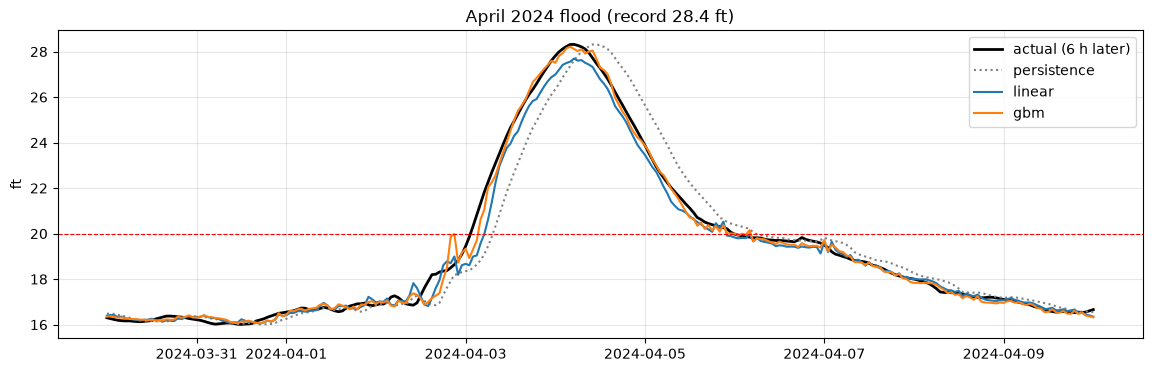

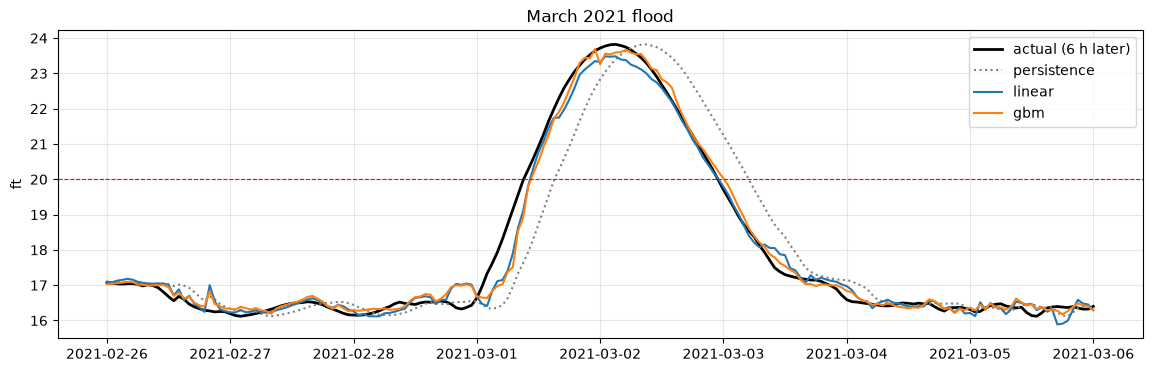

In [27]:
def plot_event(start, end, title=""):
    s = slice(pd.Timestamp(start, tz="UTC"), pd.Timestamp(end, tz="UTC"))
    g = oof_gbm.loc[s]
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(g.index, g.y, "k", lw=2, label="actual (6 h later)")
    ax.plot(g.index, g.point_now, color="gray", ls=":", label="persistence")
    ax.plot(g.index, oof_lin.reindex(g.index)["pred"], label="linear")
    ax.plot(g.index, g.pred, label="gbm")
    ax.axhline(THRESHOLD, color="red", ls="--", lw=0.8)
    ax.set_title(title); ax.set_ylabel("ft"); ax.legend(); ax.grid(alpha=0.3)
    plt.show()

plot_event("2024-03-30", "2024-04-10", "April 2024 flood (record 28.4 ft)")
plot_event("2021-02-26", "2021-03-06", "March 2021 flood")

In [28]:
lvl = df.loc[df.water_year.isin(TEST_YEARS), TARGET].dropna()
t_above = lvl.index[lvl >= THRESHOLD].to_series()
ev_id = (t_above.diff() > pd.Timedelta("24h")).cumsum()

events = t_above.groupby(ev_id).agg(["min", "max"]).rename(columns={"min": "start", "max": "end"})
events["peak"] = [lvl[s:e].max() for s, e in zip(events.start, events.end)]
events = events.reset_index(drop=True)
print(len(events), f"events at >= {THRESHOLD} ft in WY{min(TEST_YEARS)}–{max(TEST_YEARS)}")
events

12 events at >= 20 ft in WY2019–2026


,start,end,peak
0,2019-02-08 10:00:00+00:00,2019-02-09 22:00:00+00:00,24.404167
1,2019-02-13 14:00:00+00:00,2019-02-13 19:00:00+00:00,20.067500
2,2020-02-12 00:00:00+00:00,2020-02-12 00:00:00+00:00,20.007500
3,2020-02-14 07:00:00+00:00,2020-02-14 10:00:00+00:00,20.025833
4,2021-03-01 16:00:00+00:00,2021-03-03 04:00:00+00:00,23.821667
5,2022-02-05 01:00:00+00:00,2022-02-05 12:00:00+00:00,20.410833
6,2022-02-18 18:00:00+00:00,2022-02-19 21:00:00+00:00,22.905833
7,2022-02-25 20:00:00+00:00,2022-02-27 02:00:00+00:00,21.036667
8,2022-05-07 17:00:00+00:00,2022-05-08 21:00:00+00:00,21.601667
9,2024-01-29 01:00:00+00:00,2024-01-30 11:00:00+00:00,22.940833


In [32]:
grid = df.index[df.water_year.isin(TEST_YEARS)]

def alarm_series(pred, hold=1):
    """On when the prediction is >= threshold. Once on, stays on for `hold` hours."""
    raw = (pred >= THRESHOLD).reindex(grid, fill_value=False).astype(int)
    return raw.rolling(hold, min_periods=1).max().astype(bool)

def evaluate_alarm(alarm, events=events, window=24):
    w = pd.Timedelta(hours=window)
    rows = []
    for _, e in events.iterrows():
        on = alarm[e.start - w: e.start - pd.Timedelta(hours=1)]
        on = on[on]
        rows.append({"event_start": e.start, "peak": round(e.peak, 2),
                     "caught": len(on) > 0,
                     "lead_h": (e.start - on.index[0]).total_seconds() / 3600 if len(on) else np.nan})
    per_event = pd.DataFrame(rows)

    # alarm periods = consecutive "on" hours; false if they don't touch any event (incl. 24 h before it)
    period_id = (alarm != alarm.shift()).cumsum()[alarm]
    periods = alarm[alarm].index.to_series().groupby(period_id).agg(["min", "max"])
    touches = lambda s, e2: ((events.start - w <= e2) & (events.end >= s)).any()
    n_false = sum(not touches(s, e2) for s, e2 in zip(periods["min"], periods["max"]))

    summary = {"caught": f"{per_event.caught.sum()}/{len(per_event)}",
               "median_lead_h": per_event.lead_h.median(),
               "false_alarms": n_false,
               "alarm_periods": len(periods)}
    return summary, per_event

In [33]:
methods = {
    "persistence": oof_gbm["point_now"],
    "persistence+trend": pred_trend.reindex(oof_gbm.index),
    "linear": oof_lin["pred"],
    "gbm": oof_gbm["pred"],
    "gbm (hold 6 h)": oof_gbm["pred"],
}

results, details = {}, {}
for name, pred in methods.items():
    hold = 6 if "hold" in name else 1
    results[name], details[name] = evaluate_alarm(alarm_series(pred, hold))

pd.DataFrame(results).T

,caught,median_lead_h,false_alarms,alarm_periods
persistence,0/12,NaN,0,13
persistence+trend,12/12,5.5,5,20
linear,8/12,3.0,0,9
gbm,11/12,5.0,1,16
gbm (hold 6 h),11/12,5.0,1,13


In [34]:
cmp = details["gbm (hold 6 h)"][["event_start", "peak", "caught", "lead_h"]].rename(
    columns={"caught": "gbm_caught", "lead_h": "gbm_lead"})
cmp["linear_caught"] = details["linear"]["caught"]
cmp["linear_lead"] = details["linear"]["lead_h"]

# max level the gbm predicted in the 24 h before each event
cmp["gbm_max_pred"] = [
    oof_gbm["pred"].loc[s - pd.Timedelta("24h"): s - pd.Timedelta("1h")].max() for s in cmp.event_start
]
cmp.round(2)

/tmp/ipykernel_252011/656187514.py:10: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  cmp.round(2)


,event_start,peak,gbm_caught,gbm_lead,linear_caught,linear_lead,gbm_max_pred
0,2019-02-08 10:00:00+00:00,24.40,True,5.0,True,3.0,21.61
1,2019-02-13 14:00:00+00:00,20.07,True,10.0,True,5.0,20.46
2,2020-02-12 00:00:00+00:00,20.01,False,NaN,False,NaN,19.87
3,2020-02-14 07:00:00+00:00,20.03,True,3.0,False,NaN,20.03
4,2021-03-01 16:00:00+00:00,23.82,True,5.0,True,5.0,21.71
5,2022-02-05 01:00:00+00:00,20.41,True,6.0,True,4.0,20.36
6,2022-02-18 18:00:00+00:00,22.91,True,3.0,False,NaN,21.16
7,2022-02-25 20:00:00+00:00,21.04,True,6.0,False,NaN,20.50
8,2022-05-07 17:00:00+00:00,21.60,True,4.0,True,1.0,21.44
9,2024-01-29 01:00:00+00:00,22.94,True,4.0,True,2.0,21.64


In [35]:
levels = [19.0, 19.25, 19.5, 19.75, 20.0, 20.25, 20.5]
rows = []
for name, pred in [("persistence+trend", methods["persistence+trend"]), ("gbm", oof_gbm["pred"])]:
    for lv in levels:
        raw = (pred >= lv).reindex(grid, fill_value=False).astype(int)
        alarm = raw.rolling(6, min_periods=1).max().astype(bool)      # 6 h hold for both
        s, _ = evaluate_alarm(alarm)
        rows.append({"method": name, "alarm_level_ft": lv, **s})
sweep = pd.DataFrame(rows)
sweep.pivot(index="alarm_level_ft", columns="method", values=["caught", "median_lead_h", "false_alarms"])

caught                   median_lead_h                   false_alarms                  
method            gbm persistence+trend           gbm persistence+trend          gbm persistence+trend
alarm_level_ft                                                                                        
19.00           12/12             12/12          10.0               7.0           11                14
19.25           12/12             12/12           9.5               6.5           10                10
19.50           12/12             12/12           7.0               6.0            6                 7
19.75           12/12             12/12           6.0               5.5            3                 7
20.00           11/12             12/12           5.0               5.5            1                 5
20.25           10/12             12/12           4.0               4.0            1                 3
20.50            8/12             10/12           3.5               4.0            1                 3